In [ ]:
import pandas as pd
import yfinance as yf
import arch as arch
import matplotlib.pyplot as plt
import seaborn as sd

In [ ]:
Infosys=yf.download('INFY.NS',period='10y')['Close']
Infosys=Infosys.rename(columns={'INFY.NS':'Price'})
Infosys['Return']=Infosys['Price'].pct_change().fillna(0)*100

[*********************100%***********************]  1 of 1 completed


In [ ]:
TARCH_Model=arch.arch_model(Infosys['Return'],p=1,q=1,o=1,vol='GARCH')
TARCH_Result=TARCH_Model.fit(disp='off')
print('\n             TARCH-Model Summary for Infosys')
TARCH_Result.summary()



             TARCH-Model Summary for Infosys


<class 'statsmodels.iolib.summary.Summary'>
"""
                   Constant Mean - GJR-GARCH Model Results                    
==============================================================================
Dep. Variable:                 Return   R-squared:                       0.000
Mean Model:             Constant Mean   Adj. R-squared:                  0.000
Vol Model:                  GJR-GARCH   Log-Likelihood:               -4704.73
Distribution:                  Normal   AIC:                           9419.46
Method:            Maximum Likelihood   BIC:                           9448.52
                                        No. Observations:                 2471
Date:                Thu, Oct 29 2026   Df Residuals:                     2470
Time:                        09:33:09   Df Model:                            1
                                Mean Model                                
==========================================================================
                 coef    std err          t      P>|t|    95.0% Conf. Int.
--------------------------------------------------------------------------
mu             0.0835  3.102e-02      2.691  7.121e-03 [2.268e-02,  0.144]
                              Volatility Model                             
===========================================================================
                 coef    std err          t      P>|t|     95.0% Conf. Int.
---------------------------------------------------------------------------
omega          0.3036      0.207      1.464      0.143    [ -0.103,  0.710]
alpha[1]       0.0638  3.531e-02      1.806  7.088e-02 [-5.428e-03,  0.133]
gamma[1]       0.0746  5.806e-02      1.285      0.199 [-3.919e-02,  0.188]
beta[1]        0.7956      0.116      6.861  6.845e-12    [  0.568,  1.023]
===========================================================================

Covariance estimator: robust
"""

In [ ]:
Volatility=pd.DataFrame({'Real Volatility':Infosys['Return'].abs(),
                         'TARCH Volatility':TARCH_Result.conditional_volatility})

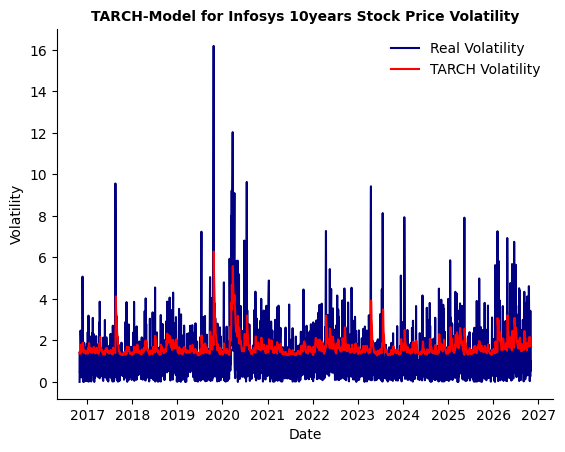

In [ ]:
sd.lineplot(Volatility,dashes=False,palette={'Real Volatility':'navy','TARCH Volatility':'red'})
plt.title('TARCH-Model for Infosys 10years Stock Price Volatility',fontsize=10,fontweight='bold')
plt.legend(frameon=False)
ax=plt.gca()
ax.spines['right'].set_visible(False)
ax.spines['top'].set_visible(False)
plt.ylabel('Volatility');